# Hipparcos-Gaia acceleration

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time

In [2]:
from exogaia.data import GaiaAstrometry, HipparcosAstrometry
from exogaia.inference import HipparcosGaiaOrbitMap
from exogaia.limits import GaiaCompleteness, HipparcosGaiaCompleteness
from exogaia.models import KeplerModel, StarModel, HipparcosGaiaPMAnomaly

The Gaia ESA Archive will be down as of 25 November 12:00 CET for preparation of the Gaia DR4 release on 2 December 12:00 CET. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


Let's analyse AF Lep, which has a high-significance acceleration in HGCA and a directly imaged giant planet.

In [3]:
source_id = 3009908378049913216
hip_id = 25486
primary_mass = (1.2, 0.06)

First we initialize the `GaiaAstrometry` object.

In [4]:
gaia_astrom = GaiaAstrometry(
    primary_mass=primary_mass,
    gaia_release="DR3",
    verbose=True
)


Gaia astrometry

Gaia release: DR3
Reference epoch: J2016.000

Primary mass (Msun): 1.20 +/- 0.06


And query Gaia DR3 for the stellar parameters.

In [5]:
param = gaia_astrom.query_source(
    source_id=source_id,
    gaia_release='DR3'
)


---------------
Querying source
---------------

Gaia release: DR3
Source ID: 3009908378049913216

RA = 81.770 deg +/- 0.012 mas
Dec = -11.901 deg +/- 0.010 mas
Parallax = 37.254 +/- 0.019 mas
Proper motion in RA = 16.915 +/- 0.018 mas/yr
Proper motion in Dec = -49.318 +/- 0.016 mas/yr
G-band magnitude = 6.210
Pseudocolor = 1.58 um-1

UWE = 1.84
RUWE = 0.92
Astrometric excess noise (mas) = 0.1273 +/- 0.0039
Non single star = 0


We will now simulate DR3 epoch astrometry with the planets parameters. Later, the AL uncertainties are used in `HipparcosGaiaOrbitMap`.

In [6]:
# AF Lep b (Franson et al. 2023)

a_rel = 8.4  # (au)
mass_2 = (3.2 * u.M_jup).to_value(u.M_sun)
parallax = 37.254  # (mas)

# Convert t_per to tau relative to the Gaia ref_epoch
t_per = Time(2456700.0, format="jd", scale="tcb")
t_ref = gaia_astrom.ref_epoch.tcb
per_years = np.sqrt(a_rel**3 / (primary_mass[0] + mass_2))
tau = ((t_per - t_ref).to_value(u.day) / (per_years * 365.25)) % 1.0

model_param = {
    "ecc": 0.24,
    "tau": tau,
    "inc": np.radians(50.0),
    "aop": np.radians(210.0),
    "pan": np.radians(66.0),
    "sma": a_rel,
}

model_param = gaia_astrom.simulate_data(
    model_param=model_param,
    mass_2=mass_2,
    flux_ratio=None,
    occ_rate=None,
    sigma_per_ccd=None,
    csv_out=None,
    reject_fraction=False,
    seed=1,
)


-------------
Simulate data
-------------

System type: binary

Primary mass (Msun): 1.20 +/- 0.06

AL scan uncertainty (per CCD) = 140.25 uas
AL scan uncertainty (per transit) = 49.58 uas

Additional parameters:
   - Primary mass (Msun) = 1.20
   - Companion mass (Msun) = 3.05e-03
   - Mass ratio = 2.55e-03
   - Flux ratio = 8.32e-10
   - Relative semi-major axis (au) = 8.40

Star model

Epoch astrometry: GaiaAstrometry

-----------------------
Calculate stellar track
-----------------------

Stellar parameters:
   - RA offset (mas) = 0.000
   - Dec offset (mas) = 0.000
   - Parallax (mas) = 37.254
   - Proper motion in RA (mas/yr) = 16.915
   - Proper motion in Dec (mas/yr) = -49.318

Kepler model

Epoch astrometry: GaiaAstrometry
Orbit reference epoch: 2016.0000

---------------------
Calculate orbit model
---------------------

Orbit parameters:
   - Period (days) = 8107.117
   - Eccentricity = 0.240
   - Relative time of periastron = 0.915
   - Semi-major axis (mas) = 312.932
   

We also have to create a `HipparcosAstrometry` object.

In [7]:
hip_astrom = HipparcosAstrometry(
    hip_id=hip_id,
    primary_mass=primary_mass,
    verbose=True
)


Hipparcos astrometry

Reference epoch: J1991.250
Primary mass (Msun): 1.20 +/- 0.06


And retrieve the Hipparcos epoch astrometry of AF Lep and the parameters from HGCA.

In [8]:
hip_astrom.retrieve_data()
hgca_data = hip_astrom.add_hgca()


-----------------------
Retrieve Hipparcos data
-----------------------

Hipparcos ID: 25486
Gaia DR3 ID: 3009908378049913216
Reference epoch: J1991.250

Solution type: 5 (5-parameters)
F2: 2.15

RA = 81.770 deg +/- 0.370 mas
Dec = -11.901 deg +/- 0.290 mas
Parallax = 36.980 +/- 0.480 mas
Proper motion in RA = 17.550 +/- 0.360 mas/yr
Proper motion in Dec = -50.230 +/- 0.350 mas/yr
Variance inflation: 0.00 mas

Hp-band magnitude = 6.421

Accepted scans: 80
Rejected scans: 0

Reference: van Leeuwen F. (2007), ASSL, 350

------------------------------------------------
Retrieve Hipparcos–Gaia Catalog of Accelerations
------------------------------------------------

Hipparcos ID: 25486
Gaia DR3 ID: 3009908378049913216
HGCA chi-square: 77.25

Hipparcos proper motion:
   PM RA  = 17.3981 +/- 0.5532 mas/yr
   PM Dec = -49.7249 +/- 0.5103 mas/yr

Gaia proper motion:
   PM RA  = 16.9150 +/- 0.0251 mas/yr
   PM Dec = -49.3180 +/- 0.0214 mas/yr

Hipparcos-Gaia proper motion:
   PM RA  = 17.1190

With the simulated Gaia DR3 data and the Hipparcos epoch astrometry, we can calculate the Hipparcos-Gaia proper motion vectors. This is done with the `HipparcosGaiaPMAnomaly` model.

In [9]:
hip_gaia = HipparcosGaiaPMAnomaly(
    gaia_astrometry=gaia_astrom,
    hipparcos_astrometry=hip_astrom,
    verbose=True
)


Hipparcos-Gaia proper-motion anomalies

Gaia input source ID: None
Hipparcos ID: 25486

HGCA Gaia DR3 ID: 3009908378049913216
HGCA catalog chi2: 77.24609375

HGCA central epochs (RA, Dec) in Julian years:
   - Hipparcos: [1991.0621 1991.1765]
   - Gaia: [2016.2087 2016.2385]
   - Baseline: [25.1467 25.0621]

HGCA proper motions (mu_alpha*, mu_dec) in mas/yr:
   - Hipparcos: [ 17.398075 -49.72488 ]
   - HG: [ 17.118963 -49.192383]
   - Gaia: [ 16.915014 -49.31799 ]
   - Gaia - HG: [-0.20394897 -0.12560654]

Orbital reference epoch (TCB): 2016.00


Let's first calculate the proper motion anomaly for the simulated orbit.

In [10]:
hip_gaia.calc_pm_anomaly(model_param=model_param, add_noise=False)


--------------------------------------
Calculate Hipparcos-Gaia proper motion
--------------------------------------

Model parameters:
   - ecc = 0.24
   - tau = 0.92
   - inc = 0.87
   - aop = 0.52
   - pan = 1.15
   - sma = 0.79
   - parallax = 37.25
   - pm_ra = 16.92
   - pm_dec = -49.32
   - ra_offset = 0.00
   - dec_offset = 0.00
   - per = 8107.12

Hipparcos orbital PM:
   RA  = -0.008 mas/yr
   Dec = -0.209 mas/yr

Gaia orbital PM:
   RA  = -0.206 mas/yr
   Dec = -0.147 mas/yr

Hipparcos-Gaia long-term PM:
   RA  = -0.013 mas/yr
   Dec = -0.021 mas/yr

Hipparcos-HG PM anomaly:
   RA  = 0.005 mas/yr
   Dec = -0.188 mas/yr
   Amplitude = 0.188 mas/yr

Gaia-HG PM anomaly:
   RA  = -0.1930 mas/yr
   Dec = -0.1264 mas/yr
   Amplitude = 0.2307 mas/yr


And we also calculate the $\chi^2$, which can be compared with the actual value in HGCA.

In [11]:
_ = hip_gaia.calc_chi2(model_param=model_param)


--------------------------
Calculate HGCA chi-squared
--------------------------

Model parameters:
   - ecc = 0.24
   - tau = 0.92
   - inc = 0.87
   - aop = 0.52
   - pan = 1.15
   - sma = 0.79
   - parallax = 37.25
   - pm_ra = 16.92
   - pm_dec = -49.32
   - ra_offset = 0.00
   - dec_offset = 0.00
   - per = 8107.12

Hipparcos-HG anomaly:
   - Null-model chi2 = 1.14
   - Orbital-model chi2 = 0.56
   - Delta chi2 = 0.58

Gaia-HG anomaly:
   - Null-model chi2 = 77.25
   - Orbital-model chi2 = 0.13
   - Delta chi2 = 77.12

Joint anomalies:
   - Null-model chi2 = 78.29
   - Orbital-model chi2 = 0.69
   - Delta chi2 = 77.61


Let's now plot the orbit and the orbital proper motion vectors.


-------------------------
Plot Hipparcos-Gaia orbit
-------------------------

Model parameters:
   - ecc = 0.24
   - tau = 0.92
   - inc = 0.87
   - aop = 0.52
   - pan = 1.15
   - sma = 0.79
   - parallax = 37.25
   - pm_ra = 16.92
   - pm_dec = -49.32
   - ra_offset = 0.00
   - dec_offset = 0.00
   - per = 8107.12

Output file: hip-gaia.png


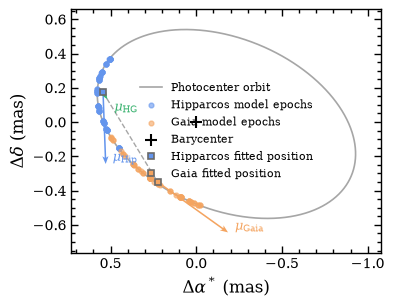

In [12]:
fig = hip_gaia.plot_orbit(
    model_param=model_param,
    vector_years=2.0,
    plot_file='hip-gaia.png'
)

Next, we will make a prediction of where the companion is most likely to be located, by comparing the simulated Hipparcos-Gaia proper motion anomaly with the values from HGCA.

In [13]:
orbit_map = HipparcosGaiaOrbitMap(
    gaia_astrometry=gaia_astrom,
    hipparcos_astrometry=hip_astrom
)

First with sample a million orbits.

In [14]:
orbit_map.sample_orbits(
    n_samples=1_000_000,
    mass_range=(0.001, 0.2),
    sma_range=(0.1, 50.0),
    seed=1
)


-------------
Sample orbits
-------------



  0%|          | 0/500 [00:00<?, ?it/s]


Minimum chi-squared: 0.19
Effective sample size: 4170 of 1000000


And now plot a likelihood map.


-------------
Plot position
-------------

Epoch = 2022.80
Filter width= 1.00

Output file: position.png


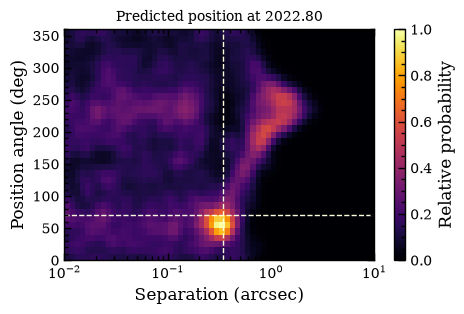

In [15]:
fig = orbit_map.plot_position(
    epoch=Time("2022-10-20", format="iso", scale="utc"),
    filter_sigma=1.0,
    true_position=(0.34, 70.0),
    plot_file='position.png'
)

Finally, let's estimate the completeness in companion mass and separation.

In [16]:
compl = HipparcosGaiaCompleteness(
    gaia_astrometry=gaia_astrom,
    hipparcos_astrometry=hip_astrom
)


-------------------------------------
Calculate Hipparcos-Gaia completeness
-------------------------------------

Detection type: gaia
Detection significance: 3.0 sigma
Detection degrees of freedom: 2
Chi-square threshold: 11.83



  0%|          | 0/900 [00:00<?, ?it/s]


Output file: compl_map_gaia.png


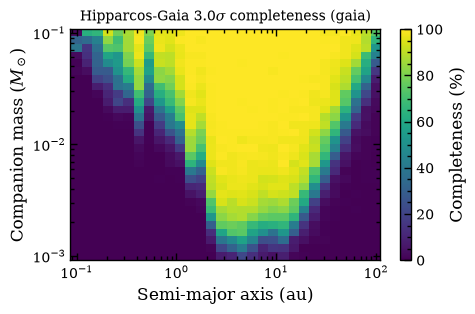

In [17]:
fig = compl.calc_completeness(
    det_type="gaia",
    n_sigma=3.0,
    n_samples=200,
    mass_points=np.logspace(-3, -1, 30),
    sma_points=np.logspace(-1, 2, 30),
    plot_file="compl_map_gaia.png"
)